In [1]:
pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from src.data import load_clean
from src.features import add_distance_features, add_listing_features

df = add_listing_features(add_distance_features(load_clean()))

num_cols = ["accommodates", "bedrooms", "beds", "latitude", "longitude",
            "dist_colosseum_km", "dist_termini_km", "dist_st_peters_km",
            "dist_pantheon_km", "dist_trevi_km", "dist_nearest_landmark_km",
            "n_amenities", "bathrooms_num", "minimum_nights"]
cat_cols = ["room_type", "neighbourhood_cleansed", "property_type"]

X = df[num_cols + cat_cols].copy()
for c in cat_cols:
    X[c] = X[c].astype("category")
y = df["log_price"]

In [3]:
model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05,
                          num_leaves=31, random_state=42, verbose=-1)
model.fit(X, y)

Xs = X.sample(5000, random_state=42)     # выборка, чтобы считалось быстро
explainer = shap.TreeExplainer(model)
sv = explainer(Xs)

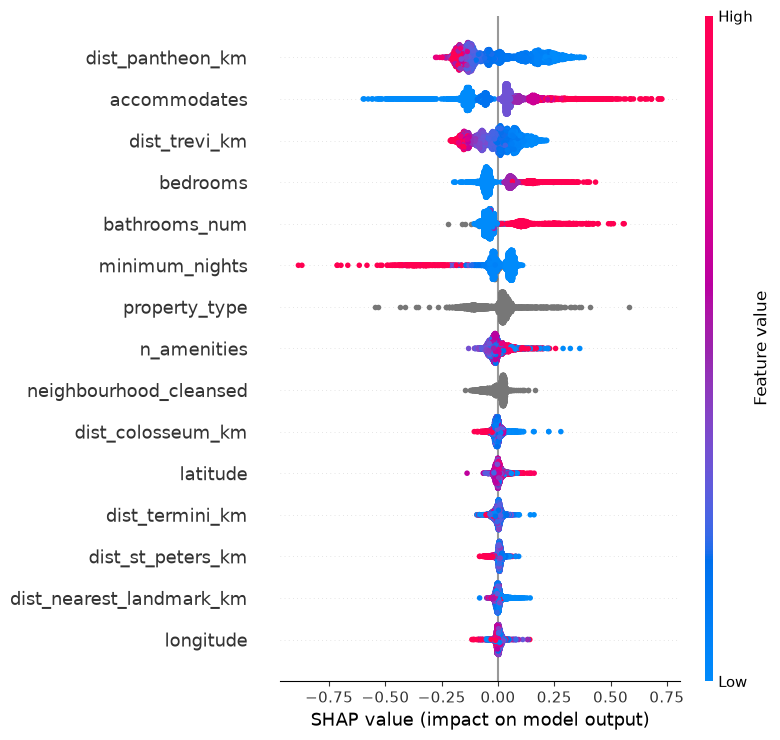

In [4]:
shap.summary_plot(sv.values, Xs, show=False, max_display=15)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

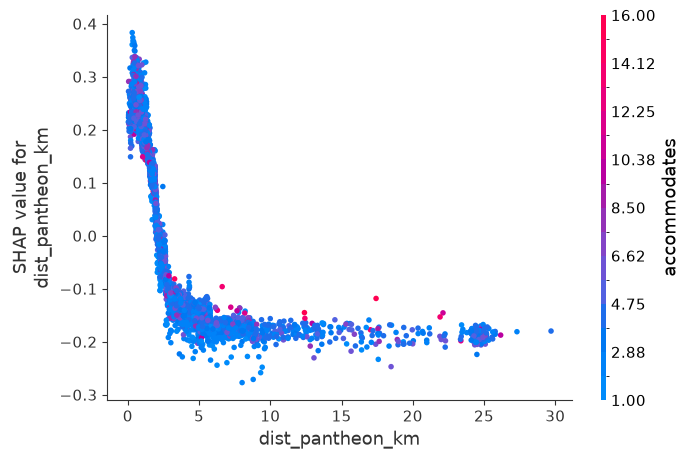

In [5]:
shap.dependence_plot("dist_pantheon_km", sv.values, Xs,
                     interaction_index="accommodates", show=False)
plt.savefig("../reports/figures/shap_pantheon.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
oof = np.zeros(len(df))
for tr, te in GroupKFold(n_splits=5).split(X, y, df["host_id"]):
    m = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05,
                          num_leaves=31, random_state=42, verbose=-1)
    m.fit(X.iloc[tr], y.iloc[tr])
    oof[te] = m.predict(X.iloc[te])

df["pred"] = np.expm1(oof)
df["err"] = df["pred"] - df["price"]            # плюс: завысили, минус: занизили
df["abs_err"] = df["err"].abs()
df["ape"] = df["abs_err"] / df["price"] * 100
print("MAE:", df["abs_err"].mean().round(1))      # должно быть ~64.1

MAE: 64.1


In [7]:
df["price_bin"] = pd.qcut(df["price"], 5)
print(df.groupby("price_bin", observed=True)[["err", "abs_err", "ape"]].median().round(1))

print(df.groupby("room_type")[["err", "abs_err", "ape"]].median().round(1))

df["acc_bin"] = pd.cut(df["accommodates"], [0, 2, 4, 6, 100])
print(df.groupby("acc_bin", observed=True)[["err", "abs_err", "ape"]].median().round(1))

                              err  abs_err   ape
price_bin                                       
(20.058999999999997, 124.0]  27.3     28.2  29.5
(124.0, 165.0]               14.4     23.5  16.3
(165.0, 214.0]                4.2     28.3  15.1
(214.0, 301.906]            -17.3     41.8  16.7
(301.906, 2000.0]           -87.8    104.3  26.0
                  err  abs_err   ape
room_type                           
Entire home/apt   4.9     37.9  19.0
Hotel room        4.8     54.1  27.2
Private room      2.7     29.8  21.8
Shared room      29.1     51.3  68.0
          err  abs_err   ape
acc_bin                     
(0, 2]    3.8     28.1  20.1
(2, 4]    4.3     33.8  18.6
(4, 6]    5.8     49.0  20.3
(6, 100]  3.9     90.5  23.1


In [8]:
cols = ["price", "pred", "err", "room_type", "accommodates",
        "neighbourhood_cleansed", "dist_pantheon_km", "n_amenities"]
df.sort_values("abs_err", ascending=False)[cols].head(20).round(1)

,price,pred,err,room_type,accommodates,neighbourhood_cleansed,dist_pantheon_km,n_amenities
16559,2000.0,158.7,-1841.3,Entire home/apt,2,XI Arvalia/Portuense,3.8,51
21791,2000.0,160.0,-1840.0,Private room,2,I Centro Storico,1.8,30
21843,2000.0,161.5,-1838.5,Private room,2,I Centro Storico,1.8,31
9526,1959.3,125.0,-1834.3,Private room,2,I Centro Storico,2.9,21
28506,2000.0,210.4,-1789.6,Entire home/apt,4,XII Monte Verde,4.5,14
33177,1879.2,113.7,-1765.5,Entire home/apt,4,XIII Aurelia,11.1,20
2378,1974.8,251.2,-1723.6,Entire home/apt,7,II Parioli/Nomentano,2.7,39
22180,2000.0,279.5,-1720.5,Entire home/apt,6,I Centro Storico,1.7,36
14376,1863.3,177.7,-1685.6,Entire home/apt,4,VII San Giovanni/Cinecittà,3.2,42
1543,1755.0,105.7,-1649.3,Private room,1,VII San Giovanni/Cinecittà,3.3,31


In [9]:
top = df["price"] > 1000
print("share of listings > 1000:", round(top.mean() * 100, 1), "%")
print("share of total absolute error from them:", round(df.loc[top, "abs_err"].sum() / df["abs_err"].sum() * 100, 1), "%")
print("median absolute error:", round(df["abs_err"].median(), 1))
print("MAE without prices > 1000:", round(df.loc[~top, "abs_err"].mean(), 1))

share of listings > 1000: 1.0 %
share of total absolute error from them: 12.2 %
median absolute error: 35.7
MAE without prices > 1000: 56.8
